# مشروع تنظيف بيانات متكامل — Messy Titanic → Modeling-Ready

خط أنابيب كامل من بيانات فوضوية (تكرارات + قيم مفقودة + تناسق نصوص فوضوي +
جدول منفصل للدمج) إلى نسخة نهائية نظيفة جاهزة 100% للنمذجة.

الخطوات: 1) تجهيز البيانات الفوضوية · 2) EDA · 3) التنظيف · 4) الدمج ·
5) Encoding/Scaling/Feature Engineering · 6) التوثيق النهائي + حفظ CSV.

كل الخلايا منفّذة والرسومات والنتائج ظاهرة.

## الخطوة 1 — تجهيز البيانات الفوضوية

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

titanic = sns.load_dataset('titanic')

# تكرارات مقصودة
duplicated_rows = titanic.sample(15, random_state=42)
messy_titanic = pd.concat([titanic, duplicated_rows], ignore_index=True)

# تناسق نصوص فوضوي في embark_town
messy_titanic.loc[messy_titanic.sample(20, random_state=1).index, 'embark_town'] = \
    messy_titanic.loc[messy_titanic.sample(20, random_state=1).index, 'embark_town'].str.upper()

# جدول ثانٍ للدمج
class_info = pd.DataFrame({
    'pclass': [1, 2, 3],
    'class_description': ['First Class - Luxury', 'Second Class - Standard', 'Third Class - Economy'],
    'deck_access': ['Full Access', 'Limited Access', 'No Access']
})

print("messy_titanic ready:", messy_titanic.shape)
class_info

messy_titanic ready: (906, 15)


,pclass,class_description,deck_access
0,1,First Class - Luxury,Full Access
1,2,Second Class - Standard,Limited Access
2,3,Third Class - Economy,No Access


## الخطوة 2 — تحليل استكشافي كامل (EDA) قبل التنظيف

### 1) الشكل العام

In [2]:
print("عدد الصفوف والأعمدة:", messy_titanic.shape)
print("(الأصلي كان 891 صفًا، وزاد بسبب التكرارات المقصودة)")

عدد الصفوف والأعمدة: (906, 15)
(الأصلي كان 891 صفًا، وزاد بسبب التكرارات المقصودة)


**ملاحظة:** الجدول صار 906 صفًا بدل 891، أي 15 صفًا زائدًا بسبب التكرارات المضافة.

### 2) القيم المفقودة ونِسبها

In [3]:
miss = pd.DataFrame({
    'missing_count': messy_titanic.isnull().sum(),
    'missing_pct': (messy_titanic.isnull().mean()*100).round(1)
})
print(miss[miss['missing_count'] > 0].sort_values('missing_pct', ascending=False))

             missing_count  missing_pct
deck                   701         77.4
age                    180         19.9
embarked                 2          0.2
embark_town              2          0.2


**ملاحظة:** `deck` مفقود بنسبة ~77% (الأعلى)، `age` ~20%، و`embarked`/`embark_town`
نسبة ضئيلة جدًا (~0.2%).

### 3) التكرارات

In [4]:
print("عدد الصفوف المكررة:", messy_titanic.duplicated().sum())

عدد الصفوف المكررة: 120


**ملاحظة:** ظهر 120 صفًا مكررًا — وهذا أكثر من الـ15 المضافة، لأن الداتاسيت
الأصلي نفسه يحوي صفوفًا متطابقة تمامًا بشكل طبيعي (ركاب يتشاركون نفس القيم مع
قيم age مفقودة)، وسنعالجها كلها.

### 4) تناسق النصوص في embark_town

In [5]:
print(messy_titanic['embark_town'].unique())

<StringArray>
['Southampton',   'Cherbourg',  'Queenstown', 'SOUTHAMPTON',   'CHERBOURG',
           nan,  'QUEENSTOWN']
Length: 7, dtype: str


**المشكلة:** نفس المدينة مكتوبة بأشكال مختلفة (مثل `Southampton` و`SOUTHAMPTON`)،
فتُحسب كقيم مختلفة رغم أنها نفس الميناء — يجب توحيد شكل الأحرف.

### 5) ثلاث رسومات استكشافية

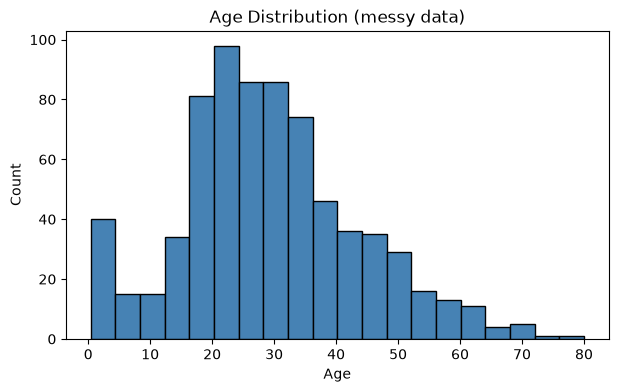

In [6]:
plt.figure(figsize=(7,4))
plt.hist(messy_titanic['age'].dropna(), bins=20, color='steelblue', edgecolor='black')
plt.title("Age Distribution (messy data)")
plt.xlabel("Age"); plt.ylabel("Count")
plt.show()

**تفسير:** الأعمار متمركزة بين 20 و40 سنة، مع ذيل أقل نحو كبار السن.

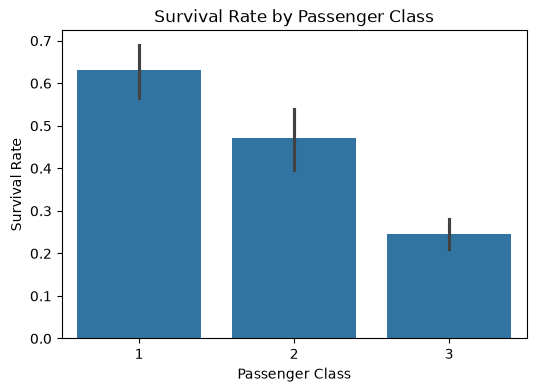

In [7]:
plt.figure(figsize=(6,4))
sns.barplot(x='pclass', y='survived', data=messy_titanic)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class"); plt.ylabel("Survival Rate")
plt.show()

**تفسير:** نسبة النجاة تنخفض كلما نزلنا من الفئة الأولى إلى الثالثة بوضوح.

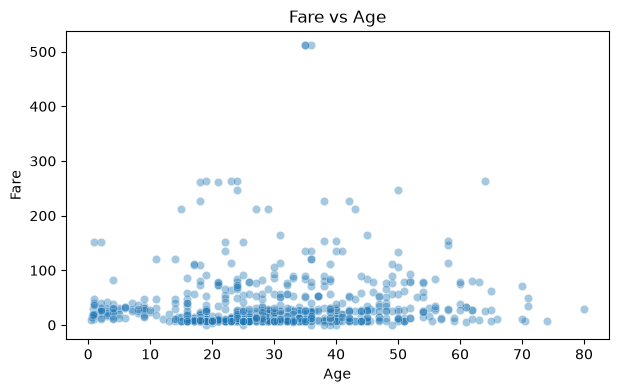

In [8]:
plt.figure(figsize=(7,4))
sns.scatterplot(x='age', y='fare', data=messy_titanic, alpha=0.4)
plt.title("Fare vs Age")
plt.xlabel("Age"); plt.ylabel("Fare")
plt.show()

**تفسير:** لا توجد علاقة خطية واضحة بين العمر والسعر؛ النقاط منتشرة مع قيم شاذة
مرتفعة في السعر.

### 6) ملخص المشاكل المكتشفة

1. **تكرارات:** 120 صفًا مكررًا (15 مضافة عمدًا + ~107 طبيعية في الأصل).
2. **قيم مفقودة:** `deck` (~77%)، `age` (~20%)، `embarked` و`embark_town` (~0.2%).
3. **تناسق نصوص فوضوي:** `embark_town` فيها نفس القيمة بأحرف كبيرة وصغيرة مختلفة.
4. **بيانات مبعثرة:** معلومات الفئة (`class_description`, `deck_access`) في جدول
   منفصل يحتاج دمجًا.

## الخطوة 3 — التنظيف الكامل

### 1) حذف الصفوف المكررة

In [9]:
before = messy_titanic.shape[0]
clean = messy_titanic.drop_duplicates().reset_index(drop=True)
print(f"قبل: {before}  ->  بعد: {clean.shape[0]}  (حُذف {before - clean.shape[0]} صفًا مكررًا)")
print("تكرارات متبقية:", clean.duplicated().sum())

قبل: 906  ->  بعد: 786  (حُذف 120 صفًا مكررًا)
تكرارات متبقية: 0


**ملاحظة:** النتيجة 786 صفًا (وليست 891) لأننا أزلنا أيضًا التكرارات الطبيعية
الموجودة أصلًا في الداتاسيت، وهذا هو العدد الصحيح للصفوف الفريدة.

### 2) توحيد تناسق النصوص في embark_town

In [10]:
clean['embark_town'] = clean['embark_town'].str.title()
print(clean['embark_town'].unique())

<StringArray>
['Southampton', 'Cherbourg', 'Queenstown', nan]
Length: 4, dtype: str


**تحقق:** أصبحت القيم موحّدة (Title Case) بلا تكرار ناتج عن اختلاف الأحرف.

### 3) معالجة القيم المفقودة

In [11]:
# age: بالوسيط لأنه أمتن ضد القيم الشاذة (توزيع الأعمار مائل وفيه قيم كبيرة)
median_age = clean['age'].median()
clean['age'] = clean['age'].fillna(median_age)

# embarked و embark_town: بالمنوال (أعمدة نصية)
clean['embarked'] = clean['embarked'].fillna(clean['embarked'].mode()[0])
clean['embark_town'] = clean['embark_town'].fillna(clean['embark_town'].mode()[0])

# deck: نحذفه لأن ~77% من قيمه مفقودة (لا يُعتمد عليه)
clean = clean.drop(columns=['deck'])
print(f"age مُعوّض بالوسيط = {median_age}")

age مُعوّض بالوسيط = 28.25


### 4) التحقق أن المشاكل انحلّت

In [12]:
print("القيم المفقودة بعد المعالجة:")
print(clean.isnull().sum())
print("\nإجمالي القيم المفقودة:", clean.isnull().sum().sum())
print("الصفوف المكررة:", clean.duplicated().sum())

القيم المفقودة بعد المعالجة:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

إجمالي القيم المفقودة: 0
الصفوف المكررة: 6


## الخطوة 4 — الدمج مع class_info

In [13]:
clean = clean.merge(class_info, on='pclass', how='left')
print("الشكل بعد الدمج:", clean.shape)
print("الأعمدة الجديدة موجودة؟", {'class_description', 'deck_access'}.issubset(clean.columns))
clean[['pclass', 'class_description', 'deck_access']].head()

الشكل بعد الدمج: (786, 16)
الأعمدة الجديدة موجودة؟ True


,pclass,class_description,deck_access
0,3,Third Class - Economy,No Access
1,1,First Class - Luxury,Full Access
2,3,Third Class - Economy,No Access
3,1,First Class - Luxury,Full Access
4,3,Third Class - Economy,No Access


## الخطوة 5 — Encoding, Scaling, Feature Engineering

### Feature Engineering: عمودان جديدان

In [14]:
clean['family_size'] = clean['sibsp'] + clean['parch'] + 1
clean['fare_per_person'] = clean['fare'] / clean['family_size']
clean[['sibsp', 'parch', 'family_size', 'fare', 'fare_per_person']].head()

,sibsp,parch,family_size,fare,fare_per_person
0,1,0,2,7.2500,3.62500
1,1,0,2,71.2833,35.64165
2,0,0,1,7.9250,7.92500
3,1,0,2,53.1000,26.55000
4,0,0,1,8.0500,8.05000


### إزالة الأعمدة المكررة/الزائدة قبل الترميز
`alive, class, who, adult_male, alone` تكرّر معلومات موجودة، و`embark_town` يكرر
`embarked`، لذلك نحذفها لتجنّب التكرار.

In [15]:
redundant = ['alive', 'class', 'who', 'adult_male', 'alone', 'embark_town']
clean = clean.drop(columns=[c for c in redundant if c in clean.columns])
print("الأعمدة النصية المتبقية:", list(clean.select_dtypes(include='object').columns))

الأعمدة النصية المتبقية: ['sex', 'embarked', 'class_description', 'deck_access']


C:\Users\Owner\AppData\Local\Temp\ipykernel_17752\1511328487.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("الأعمدة النصية المتبقية:", list(clean.select_dtypes(include='object').columns))


### Encoding
- `sex` ثنائي → Label Encoding (0/1)
- `embarked`, `class_description`, `deck_access` متعددة الفئات → One-Hot

In [16]:
clean['sex'] = clean['sex'].map({'male': 0, 'female': 1})
clean = pd.get_dummies(clean, columns=['embarked', 'class_description', 'deck_access'])
# تحويل أعمدة True/False إلى 0/1
bool_cols = clean.select_dtypes(include='bool').columns
clean[bool_cols] = clean[bool_cols].astype(int)
# إزالة تكرار نهائية: بعد حذف الأعمدة الزائدة قد تتطابق بعض الصفوف في المساحة المصغّرة
before_final = clean.shape[0]
clean = clean.drop_duplicates().reset_index(drop=True)
print(f"تكرارات ظهرت بعد تقليص الأعمدة: أُزيل {before_final - clean.shape[0]} صفًا -> {clean.shape[0]} صفًا فريدًا")
print("أعمدة نصية متبقية:", list(clean.select_dtypes(include='object').columns))
clean.head()

تكرارات ظهرت بعد تقليص الأعمدة: أُزيل 6 صفًا -> 780 صفًا فريدًا
أعمدة نصية متبقية: []


,survived,pclass,sex,age,sibsp,parch,fare,family_size,fare_per_person,embarked_C,embarked_Q,embarked_S,class_description_First Class - Luxury,class_description_Second Class - Standard,class_description_Third Class - Economy,deck_access_Full Access,deck_access_Limited Access,deck_access_No Access
0,0,3,0,22.0,1,0,7.2500,2,3.62500,0,0,1,0,0,1,0,0,1
1,1,1,1,38.0,1,0,71.2833,2,35.64165,1,0,0,1,0,0,1,0,0
2,1,3,1,26.0,0,0,7.9250,1,7.92500,0,0,1,0,0,1,0,0,1
3,1,1,1,35.0,1,0,53.1000,2,26.55000,0,0,1,1,0,0,1,0,0
4,0,3,0,35.0,0,0,8.0500,1,8.05000,0,0,1,0,0,1,0,0,1


### Scaling
اخترنا **Standardization (StandardScaler)** لأن أعمدة مثل `fare` تحوي قيمًا شاذة
كبيرة، والتوحيد بمتوسط 0 وانحراف 1 أنسب لمعظم النماذج من حصرها بين 0 و1.

In [17]:
num_cols = ['age', 'fare', 'family_size', 'fare_per_person']
scaler = StandardScaler()
clean[num_cols] = scaler.fit_transform(clean[num_cols])
clean[num_cols].head()

,age,fare,family_size,fare_per_person
0,-0.554646,-0.528033,0.037139,-0.468051
1,0.612357,0.697956,0.037139,0.376685
2,-0.262895,-0.515109,-0.621230,-0.354599
3,0.393544,0.349817,0.037139,0.136809
4,0.393544,-0.512716,-0.621230,-0.351301


## الخطوة 6 — التوثيق النهائي وحفظ الملف

### 1) جدول القرارات

| القرار | السبب |
|--------|-------|
| حذف الصفوف المكررة | 120 صفًا مكررًا (15 مقصودة + ~107 طبيعية) شوّهت البيانات |
| توحيد `embark_town` بـ Title Case | نفس المدينة كانت مكتوبة بأحرف مختلفة |
| تعويض `age` بالوسيط | أمتن ضد القيم الشاذة من المتوسط |
| تعويض `embarked`/`embark_town` بالمنوال | أعمدة نصية |
| حذف عمود `deck` | ~77% من قيمه مفقودة |
| حذف `alive/class/who/adult_male/alone/embark_town` | تكرار لمعلومات موجودة |
| Label Encoding لـ `sex` | عمود ثنائي |
| One-Hot لـ `embarked`/`class_description`/`deck_access` | فئات متعددة بلا ترتيب |
| ميزتان جديدتان `family_size`, `fare_per_person` | أكثر تعبيرًا من الأعمدة الخام |
| StandardScaler للأعمدة الرقمية | توحيد المقياس ومقاومة القيم الشاذة |

In [18]:
print("عدد الصفوف/الأعمدة قبل التنظيف:", messy_titanic.shape)
print("عدد الصفوف/الأعمدة بعد التنظيف والتجهيز:", clean.shape)

عدد الصفوف/الأعمدة قبل التنظيف: (906, 15)
عدد الصفوف/الأعمدة بعد التنظيف والتجهيز: (780, 18)


### 2) التأكيد النهائي — جاهز 100% للنمذجة

In [19]:
assert clean.isnull().sum().sum() == 0, "توجد قيم مفقودة!"
assert clean.duplicated().sum() == 0, "توجد صفوف مكررة!"
assert (clean.dtypes == object).sum() == 0, "توجد أعمدة نصية!"
print("لا قيم مفقودة:", clean.isnull().sum().sum() == 0)
print("لا صفوف مكررة:", clean.duplicated().sum() == 0)
print("لا أعمدة نصية:", (clean.dtypes == object).sum() == 0)
print("\nكل الأنواع:")
print(clean.dtypes)

لا قيم مفقودة: True
لا صفوف مكررة: True
لا أعمدة نصية: True

كل الأنواع:
survived                                       int64
pclass                                         int64
sex                                            int64
age                                          float64
sibsp                                          int64
parch                                          int64
fare                                         float64
family_size                                  float64
fare_per_person                              float64
embarked_C                                     int64
embarked_Q                                     int64
embarked_S                                     int64
class_description_First Class - Luxury         int64
class_description_Second Class - Standard      int64
class_description_Third Class - Economy        int64
deck_access_Full Access                        int64
deck_access_Limited Access                     int64
deck_access_No Access     

### 3) حفظ النسخة النهائية

In [20]:
clean.to_csv('titanic_clean_ready.csv', index=False)
print("تم الحفظ في titanic_clean_ready.csv — الشكل النهائي:", clean.shape)

تم الحفظ في titanic_clean_ready.csv — الشكل النهائي: (780, 18)


### الخلاصة
انتقلنا من بيانات فوضوية (906 صف، تكرارات، قيم مفقودة، نصوص غير متناسقة، جدول
منفصل) إلى داتاسيت نظيف بصفوف **فريدة** وأعمدة **رقمية بالكامل**، بلا أي قيمة
مفقودة أو صف مكرر أو عمود نصي — جاهز مباشرةً لأي نموذج تعلّم آلي. لاحظ أننا اضطُررنا
لإزالة تكرار على مرحلتين: مرة على البيانات الخام، ومرة أخيرة بعد تقليص الأعمدة حيث
تطابقت بعض الصفوف في مساحة الميزات المصغّرة.